In [19]:
import tensorflow as tf
import numpy as np

# Load the standard CIFAR-10 dataset
(X_train_full, y_train_full), (X_test_clean, y_test_clean) = ( 
    tf.keras.datasets.cifar10.load_data()
)

y_train_full = y_train_full.reshape(-1)
y_test_clean = y_test_clean.reshape(-1)

# Select exactly 50 training images from each class
rng = np.random.default_rng(42)

selected_indices = []

for class_id in range(10):
    class_indices = np.where(y_train_full == class_id)[0]

    chosen = rng.choice(
        class_indices,
        size=50,
        replace=False
    )

    selected_indices.extend(chosen)

selected_indices = np.array(selected_indices)
rng.shuffle(selected_indices)

# Create the variables required by the next cell
X_train_small = X_train_full[selected_indices]
y_train_small = y_train_full[selected_indices]

print("Small training images:", X_train_small.shape)
print("Small training labels:", y_train_small.shape)
print("Clean test images:", X_test_clean.shape)
print("Clean test labels:", y_test_clean.shape)
print("Images per class:", np.bincount(y_train_small))

Small training images: (500, 32, 32, 3)
Small training labels: (500,)
Clean test images: (10000, 32, 32, 3)
Clean test labels: (10000,)
Images per class: [50 50 50 50 50 50 50 50 50 50]


In [20]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

CLASS_NAMES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

SEEDS = [42, 52, 62]
EPOCHS = 60
BATCH_SIZE = 32


def set_seed(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)


def prepare_images(images):
    """Convert images to float32 in [0, 1]."""
    images = np.asarray(images)

    if images.ndim != 4 or images.shape[1:] != (32, 32, 3):
        raise ValueError(
            f"Expected image shape (N, 32, 32, 3), got {images.shape}"
        )

    if images.dtype == np.uint8 or images.max() > 1.0:
        images = images.astype("float32") / 255.0
    else:
        images = images.astype("float32")

    return images



# X_train_small, y_train_small
# X_test_clean, y_test_clean
# X_test_shifted, y_test_shifted

X_all = prepare_images(X_train_small)
y_all = np.asarray(y_train_small).reshape(-1).astype("int64")

assert len(X_all) == 500, "Expected exactly 500 training images."
assert len(y_all) == 500
assert set(np.unique(y_all)).issubset(set(range(10)))

# Fixed, stratified split: 40 train + 10 validation per class.
indices = np.arange(len(y_all))

train_idx, val_idx = train_test_split(
    indices,
    test_size=100,
    random_state=42,
    stratify=y_all
)

X_train = X_all[train_idx]
y_train = y_all[train_idx]
X_val = X_all[val_idx]
y_val = y_all[val_idx]

print("Training images:", X_train.shape, y_train.shape)
print("Validation images:", X_val.shape, y_val.shape)

print("\nClass counts in training split:")
print(np.bincount(y_train, minlength=10))

print("\nClass counts in validation split:")
print(np.bincount(y_val, minlength=10))

assert len(X_train) == 400
assert len(X_val) == 100

Training images: (400, 32, 32, 3) (400,)
Validation images: (100, 32, 32, 3) (100,)

Class counts in training split:
[40 40 40 40 40 40 40 40 40 40]

Class counts in validation split:
[10 10 10 10 10 10 10 10 10 10]


In [21]:


def generate_shifted_test(images, seed=42):
    import tensorflow as tf
    tf.random.set_seed(seed)
    np.random.seed(seed)
    corrupted = []
    
    # Layers simulating the fixed pipeline parameters
    rotation_layer = tf.keras.layers.RandomRotation(factor=25.0 / 360.0, fill_mode="reflect", seed=seed)
    contrast_layer = tf.keras.layers.RandomContrast(factor=0.2, seed=seed)
    
    for img in images:
        img_t = tf.convert_to_tensor(img, dtype=tf.float32)
        img_t = tf.expand_dims(img_t, 0)
        
        # 1. Random rotation up to +/- 25 degrees
        img_t = rotation_layer(img_t, training=True)
        # 2. Brightness changes
        img_t = tf.image.random_brightness(img_t, max_delta=0.2, seed=seed)
        # 3. Contrast changes
        img_t = contrast_layer(img_t, training=True)
        img_t = tf.squeeze(img_t, 0).numpy()
        
        # 4. Random rectangular occlusion
        h, w, _ = img_t.shape
        top = np.random.randint(0, h - 16 + 1)
        left = np.random.randint(0, w - 16 + 1)
        img_t[top:top+16, left:left+16, :] = 0.0
        
        # 5. Hidden Corruption: Channel Swap (RGB to BGR)
        img_t = img_t[:, :, ::-1]
        
        corrupted.append(img_t)
    return np.clip(np.array(corrupted), 0.0, 1.0)

print("\nSimulating shifted test set pipeline from clean dataset...")
X_test_clean = prepare_images(X_test_clean)
X_test_shifted = generate_shifted_test(X_test_clean)
print("Shifted test variables created. Shape:", X_test_shifted.shape)



Simulating shifted test set pipeline from clean dataset...
Shifted test variables created. Shape: (10000, 32, 32, 3)


In [22]:
from tensorflow.keras import layers, Model


def conv_bn_relu(x, filters, kernel_size, padding="valid"):
    x = layers.Conv2D(
        filters,
        kernel_size,
        padding=padding,
        use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return x


def inception_module(x):
    # Branch 1: 1x1 convolution
    b1 = conv_bn_relu(x, 16, 1)

    # Branch 2: reduction 1x1 -> 3x3
    b2 = conv_bn_relu(x, 16, 1)
    b2 = conv_bn_relu(b2, 24, 3, padding="same")

    # Branch 3: reduction 1x1 -> 5x5
    b3 = conv_bn_relu(x, 8, 1)
    b3 = conv_bn_relu(b3, 16, 5, padding="same")

    # Branch 4: average pooling -> 1x1 projection
    b4 = layers.AveragePooling2D(
        pool_size=3,
        strides=1,
        padding="same"
    )(x)
    b4 = conv_bn_relu(b4, 8, 1)

    return layers.Concatenate(axis=-1)([b1, b2, b3, b4])


def build_model(dropout_rate=0.4, weight_decay=0.0):
    regularizer = (
        tf.keras.regularizers.l2(weight_decay)
        if weight_decay > 0
        else None
    )

    inputs = layers.Input(shape=(32, 32, 3))

    x = layers.Conv2D(
        32, 3, padding="same", use_bias=False,
        kernel_regularizer=regularizer
    )(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = inception_module(x)
    x = layers.MaxPooling2D(pool_size=2)(x)

    x = layers.Conv2D(
        96, 3, padding="same", use_bias=False,
        kernel_regularizer=regularizer
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.MaxPooling2D(pool_size=2)(x)
    x = layers.GlobalAveragePooling2D()(x)

    if dropout_rate > 0:
        x = layers.Dropout(dropout_rate)(x)

    # Raw logits: softmax is applied inside the loss at training time.
    outputs = layers.Dense(10)(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(
            from_logits=True
        ),
        metrics=["accuracy"]
    )

    assert model.count_params() <= 1_000_000
    return model


test_model = build_model()
test_model.summary()
print("Total parameters:", test_model.count_params())

Model: "functional_50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_50      │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_400 (Conv2D) │ (None, 32, 32,    │        864 │ input_layer_50[0… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_400[0][0]  │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_400 (ReLU)    │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_402 (Conv2D) │ (None, 32, 32,    │        512 │ re_lu_400[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_404 (Conv2D) │ (None, 32, 32, 8) │        256 │ re_lu_400[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_402[0][0]  │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32, 8) │         32 │ conv2d_404[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_402 (ReLU)    │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_404 (ReLU)    │ (None, 32, 32, 8) │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average_pooling2d_… │ (None, 32, 32,    │          0 │ re_lu_400[0][0]   │
│ (AveragePooling2D)  │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_401 (Conv2D) │ (None, 32, 32,    │        512 │ re_lu_400[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_403 (Conv2D) │ (None, 32, 32,    │      3,456 │ re_lu_402[0][0]   │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_405 (Conv2D) │ (None, 32, 32,    │      3,200 │ re_lu_404[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_406 (Conv2D) │ (None, 32, 32, 8) │        256 │ average_pooling2… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_401[0][0]  │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         96 │ conv2d_403[0][0]  │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_405[0][0]

 Total params: 66,186 (258.54 KB)

 Trainable params: 65,754 (256.85 KB)

 Non-trainable params: 432 (1.69 KB)

Total parameters: 66186


In [23]:
def random_cutout(image, fraction=0.5):
    """
    Zero a random square region.
    fraction=0.5 gives a 16x16 square on a 32x32 image,
    covering 25% of its area.
    """
    height = tf.shape(image)[0]
    width = tf.shape(image)[1]

    cut_h = tf.cast(
        tf.cast(height, tf.float32) * fraction,
        tf.int32
    )
    cut_w = tf.cast(
        tf.cast(width, tf.float32) * fraction,
        tf.int32
    )

    top = tf.random.uniform(
        [], 0, height - cut_h + 1, dtype=tf.int32
    )
    left = tf.random.uniform(
        [], 0, width - cut_w + 1, dtype=tf.int32
    )

    rows = tf.range(height)[:, None]
    cols = tf.range(width)[None, :]

    inside_rows = (rows >= top) & (rows < top + cut_h)
    inside_cols = (cols >= left) & (cols < left + cut_w)
    mask = ~(inside_rows & inside_cols)

    mask = tf.cast(mask[..., None], image.dtype)
    return image * mask


def make_augmentation(config_name):
    """
    Return a function that transforms one image.

    Configurations:
      baseline: no augmentation
      geometry: flips and rotations
      photo: geometry + brightness/contrast
      full: photo + cutout
    """
    rotation = layers.RandomRotation(
        factor=25.0 / 360.0,
        fill_mode="reflect"
    )
    flip = layers.RandomFlip("horizontal")
    contrast = layers.RandomContrast(factor=0.2)

    def augment(image, label):
        if config_name == "baseline":
            return image, label

        image = flip(image)
        image = rotation(image)

        if config_name in ("photo", "full"):
            image = tf.image.random_brightness(image, max_delta=0.15)
            image = contrast(image)
            image = tf.clip_by_value(image, 0.0, 1.0)

        if config_name == "full":
            image = random_cutout(image, fraction=0.5)

        return image, label

    return augment


def make_datasets(seed, config_name):
    train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))

    train_ds = train_ds.shuffle(
        buffer_size=len(X_train),
        seed=seed,
        reshuffle_each_iteration=True
    )

    augment_fn = make_augmentation(config_name)

    train_ds = train_ds.map(
        augment_fn,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    train_ds = train_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    # Never augment the validation set.
    val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val))
    val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    return train_ds, val_ds

In [24]:
def train_one_run(config, seed, dropout_rate=0.4, weight_decay=0.0):
    set_seed(seed)

    model = build_model(
        dropout_rate=dropout_rate,
        weight_decay=weight_decay
    )

    train_ds, val_ds = make_datasets(seed, config)

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True,
            mode="min"
        )
    ]

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=callbacks,
        verbose=0
    )

    best_epoch = int(np.argmin(history.history["val_loss"]) + 1)

    best_val_loss, best_val_acc = model.evaluate(
        val_ds, verbose=0
    )

    result = {
        "config": config,
        "seed": seed,
        "best_epoch": best_epoch,
        "val_loss": float(best_val_loss),
        "val_accuracy": float(best_val_acc),
        "epochs_run": len(history.history["loss"])
    }

    return model, history, result


def plot_history(history, title):
    epochs = range(1, len(history.history["loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs, history.history["loss"], label="Train")
    axes[0].plot(epochs, history.history["val_loss"], label="Validation")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].plot(epochs, history.history["accuracy"], label="Train")
    axes[1].plot(epochs, history.history["val_accuracy"], label="Validation")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

Training config=baseline, seed=42
  val_accuracy=0.1600, val_loss=2.2952, best_epoch=1
Training config=baseline, seed=52
  val_accuracy=0.1100, val_loss=2.2953, best_epoch=1
Training config=baseline, seed=62
  val_accuracy=0.1200, val_loss=2.3045, best_epoch=2
Training config=geometry, seed=42
  val_accuracy=0.2000, val_loss=2.2942, best_epoch=1
Training config=geometry, seed=52
  val_accuracy=0.1300, val_loss=2.2923, best_epoch=2
Training config=geometry, seed=62
  val_accuracy=0.1400, val_loss=2.2968, best_epoch=2
Training config=photo, seed=42
  val_accuracy=0.1400, val_loss=2.2963, best_epoch=1
Training config=photo, seed=52
  val_accuracy=0.1400, val_loss=2.2926, best_epoch=2
Training config=photo, seed=62
  val_accuracy=0.1000, val_loss=2.2997, best_epoch=1
Training config=full, seed=42
  val_accuracy=0.1600, val_loss=2.2939, best_epoch=1
Training config=full, seed=52
  val_accuracy=0.1600, val_loss=2.2962, best_epoch=2
Training config=full, seed=62
  val_accuracy=0.1400, val_los

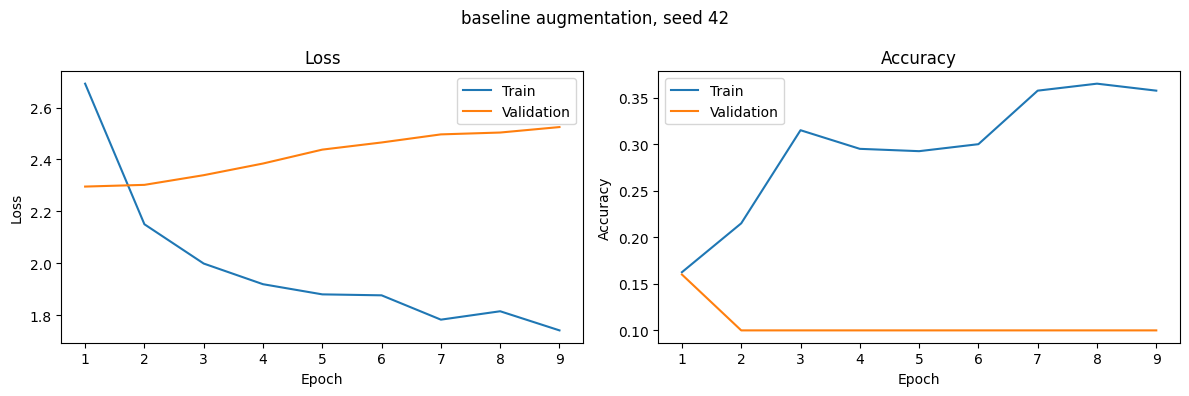

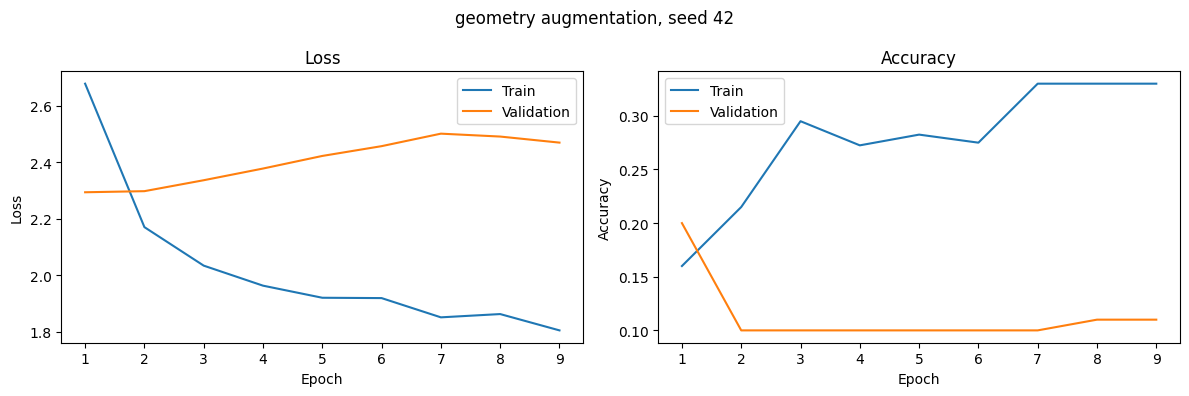

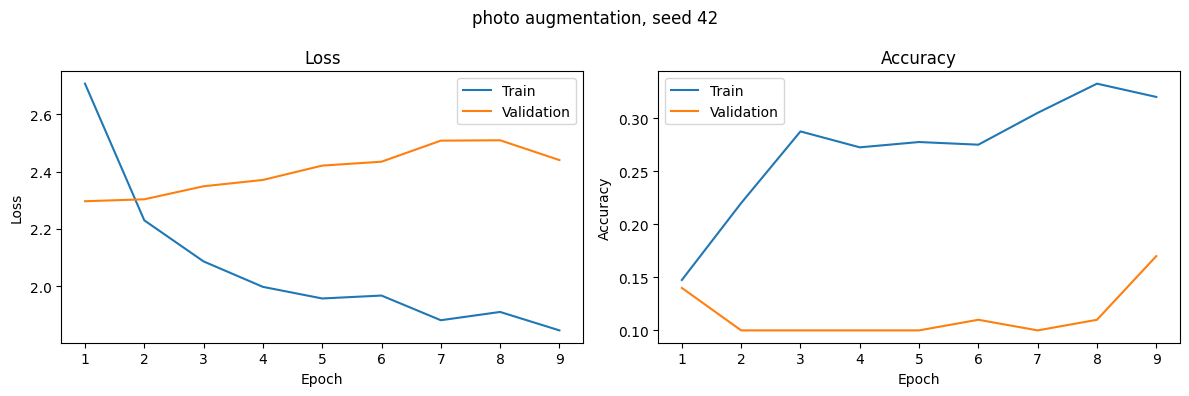

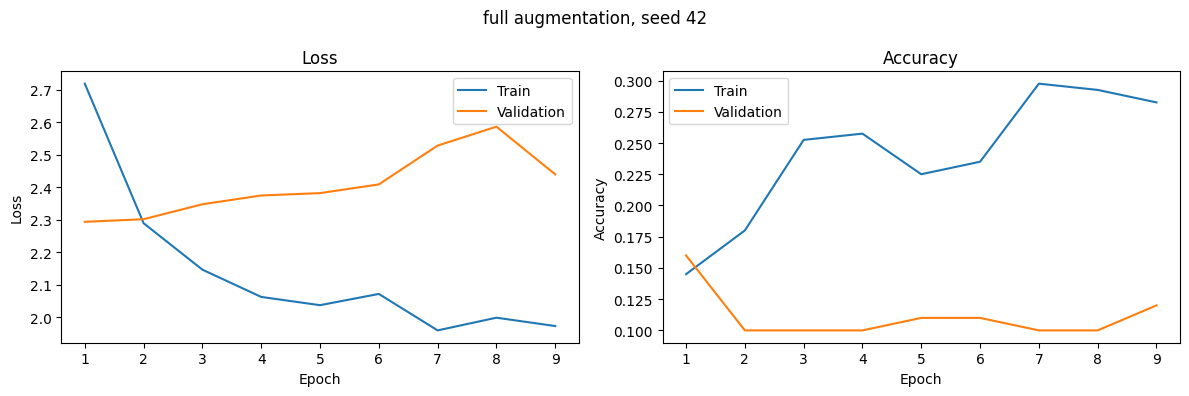

In [25]:
AUGMENTATION_CONFIGS = ["baseline", "geometry", "photo", "full"]

results = []
histories = {}
trained_models = {}

for config in AUGMENTATION_CONFIGS:
    for seed in SEEDS:
        print(f"Training config={config}, seed={seed}")

        model, history, result = train_one_run(
            config=config,
            seed=seed,
            dropout_rate=0.4,
            weight_decay=0.0
        )

        results.append(result)
        histories[(config, seed)] = history
        trained_models[(config, seed)] = model

        print(
            f"  val_accuracy={result['val_accuracy']:.4f}, "
            f"val_loss={result['val_loss']:.4f}, "
            f"best_epoch={result['best_epoch']}"
        )

results_df = pd.DataFrame(results)
print("\nAll runs:")
print(results_df.to_string(index=False))

summary = (
    results_df.groupby("config")
    .agg(
        val_accuracy_mean=("val_accuracy", "mean"),
        val_accuracy_std=("val_accuracy", "std"),
        val_loss_mean=("val_loss", "mean"),
        val_loss_std=("val_loss", "std"),
        mean_best_epoch=("best_epoch", "mean")
    )
    .sort_values("val_accuracy_mean", ascending=False)
)

print("\nValidation comparison:")
print(summary.round(4))

results_df.to_csv("cifar10_augmentation_runs.csv", index=False)
summary.to_csv("cifar10_augmentation_summary.csv")

# Plot one representative learning curve per configuration.
for config in AUGMENTATION_CONFIGS:
    plot_history(
        histories[(config, SEEDS[0])],
        f"{config} augmentation, seed {SEEDS[0]}"
    )

In [26]:
best_augmentation = summary.index[0]
print("Selected augmentation from validation:", best_augmentation)

REG_CONFIGS = {
    "no_dropout_no_l2": {
        "dropout_rate": 0.0,
        "weight_decay": 0.0
    },
    "dropout_only": {
        "dropout_rate": 0.4,
        "weight_decay": 0.0
    },
    "l2_only": {
        "dropout_rate": 0.0,
        "weight_decay": 1e-4
    },
    "dropout_and_l2": {
        "dropout_rate": 0.4,
        "weight_decay": 1e-4
    }
}

reg_results = []
reg_histories = {}
reg_models = {}

for reg_name, params in REG_CONFIGS.items():
    for seed in SEEDS:
        print(
            f"Training augmentation={best_augmentation}, "
            f"regularization={reg_name}, seed={seed}"
        )

        model, history, result = train_one_run(
            config=best_augmentation,
            seed=seed,
            dropout_rate=params["dropout_rate"],
            weight_decay=params["weight_decay"]
        )

        result["regularization"] = reg_name
        reg_results.append(result)
        reg_histories[(reg_name, seed)] = history
        reg_models[(reg_name, seed)] = model

reg_df = pd.DataFrame(reg_results)

reg_summary = (
    reg_df.groupby("regularization")
    .agg(
        val_accuracy_mean=("val_accuracy", "mean"),
        val_accuracy_std=("val_accuracy", "std"),
        val_loss_mean=("val_loss", "mean"),
        val_loss_std=("val_loss", "std")
    )
    .sort_values("val_accuracy_mean", ascending=False)
)

print("\nRegularization ablation:")
print(reg_summary.round(4))

reg_df.to_csv("cifar10_regularization_runs.csv", index=False)
reg_summary.to_csv("cifar10_regularization_summary.csv")

best_regularization = reg_summary.index[0]
print("Selected regularization:", best_regularization)

selected_params = REG_CONFIGS[best_regularization]

Selected augmentation from validation: geometry
Training augmentation=geometry, regularization=no_dropout_no_l2, seed=42
Training augmentation=geometry, regularization=no_dropout_no_l2, seed=52
Training augmentation=geometry, regularization=no_dropout_no_l2, seed=62
Training augmentation=geometry, regularization=dropout_only, seed=42
Training augmentation=geometry, regularization=dropout_only, seed=52
Training augmentation=geometry, regularization=dropout_only, seed=62
Training augmentation=geometry, regularization=l2_only, seed=42
Training augmentation=geometry, regularization=l2_only, seed=52
Training augmentation=geometry, regularization=l2_only, seed=62
Training augmentation=geometry, regularization=dropout_and_l2, seed=42
Training augmentation=geometry, regularization=dropout_and_l2, seed=52
Training augmentation=geometry, regularization=dropout_and_l2, seed=62

Regularization ablation:
                  val_accuracy_mean  val_accuracy_std  val_loss_mean  \
regularization         

Seed 42: clean accuracy=0.1893, shifted accuracy=0.1090
Seed 52: clean accuracy=0.1196, shifted accuracy=0.1062
Seed 62: clean accuracy=0.0973, shifted accuracy=0.0996

--- Part D Summary Table Information ---
Mean Clean Test Accuracy:   0.1354 ± 0.0480
Mean Shifted Test Accuracy: 0.1049 ± 0.0048

--- Part E: Classification Report (Shifted Environment) ---
              precision    recall  f1-score   support

    airplane       0.24      0.13      0.17      1000
  automobile       0.00      0.00      0.00      1000
        bird       0.00      0.00      0.00      1000
         cat       0.11      0.27      0.16      1000
        deer       0.12      0.42      0.19      1000
         dog       0.00      0.00      0.00      1000
        frog       0.00      0.00      0.00      1000
       horse       0.00      0.00      0.00      1000
        ship       0.07      0.26      0.11      1000
       truck       0.00      0.00      0.00      1000

    accuracy                           0.11  

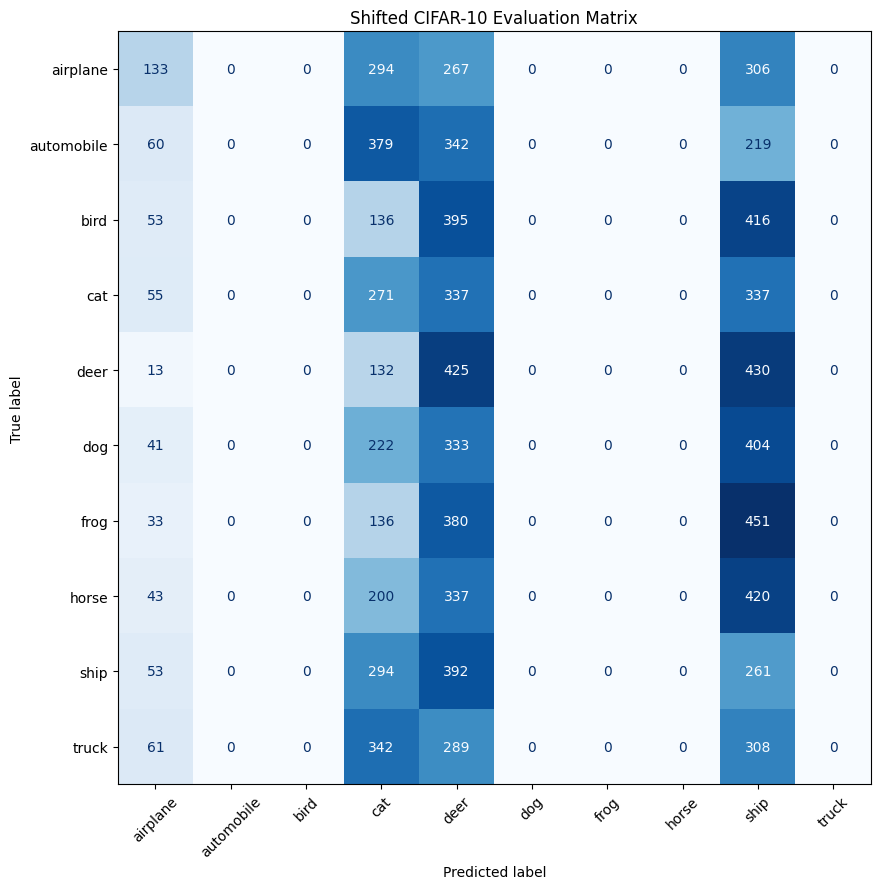


Exported training assets and run configurations metrics to project files.


In [27]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Prepare test sets

X_clean = X_test_clean
y_clean = np.asarray(y_test_clean).reshape(-1).astype("int64")

X_shift = X_test_shifted
#  Using y_test_clean because corrupting the images doesn't change their category labels
y_shift = np.asarray(y_test_clean).reshape(-1).astype("int64") 

assert len(X_clean) == 10000
assert len(X_shift) == 10000


clean_results = []
shift_results = []

# Fetch the optimized regularization instances generated above
selected_models = {
    seed: reg_models[(best_regularization, seed)]
    for seed in SEEDS
}

def get_predictions(model, images):
    logits = model.predict(images, batch_size=128, verbose=0)
    return np.argmax(logits, axis=1)

for seed in SEEDS:
    model = selected_models[seed]

    clean_pred = get_predictions(model, X_clean)
    shift_pred = get_predictions(model, X_shift)

    clean_acc = accuracy_score(y_clean, clean_pred)
    shift_acc = accuracy_score(y_shift, shift_pred)

    clean_results.append({
        "seed": seed,
        "clean_accuracy": clean_acc
    })
    shift_results.append({
        "seed": seed,
        "shifted_accuracy": shift_acc
    })

    print(
        f"Seed {seed}: "
        f"clean accuracy={clean_acc:.4f}, "
        f"shifted accuracy={shift_acc:.4f}"
    )

clean_df = pd.DataFrame(clean_results)
shift_df = pd.DataFrame(shift_results)

print("\n--- Part D Summary Table Information ---")
print(f"Mean Clean Test Accuracy:   {clean_df['clean_accuracy'].mean():.4f} ± {clean_df['clean_accuracy'].std():.4f}")
print(f"Mean Shifted Test Accuracy: {shift_df['shifted_accuracy'].mean():.4f} ± {shift_df['shifted_accuracy'].std():.4f}")

# --- PART E: ERROR ANALYSIS ---
representative_model = selected_models[42]
representative_pred = get_predictions(representative_model, X_shift)

print("\n--- Part E: Classification Report (Shifted Environment) ---")
print(
    classification_report(
        y_shift,
        representative_pred,
        labels=list(range(10)),
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

# Build Confusion Matrix metrics display
cm = confusion_matrix(y_shift, representative_pred, labels=list(range(10)))

fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)
ax.set_title("Shifted CIFAR-10 Evaluation Matrix")
plt.tight_layout()
plt.show()


representative_model.save("cifar10_inception_selected.keras")
clean_df.to_csv("cifar10_final_clean_results.csv", index=False)
shift_df.to_csv("cifar10_final_shifted_results.csv", index=False)
print("\nExported training assets and run configurations metrics to project files.")


Per-class accuracy on clean test set:
airplane    : 0.3120
automobile  : 0.0000
bird        : 0.0000
cat         : 0.4460
deer        : 0.3690
dog         : 0.0000
frog        : 0.0000
horse       : 0.0000
ship        : 0.7660
truck       : 0.0000

Clean test classification report:
              precision    recall  f1-score   support

    airplane       0.26      0.31      0.28      1000
  automobile       0.00      0.00      0.00      1000
        bird       0.00      0.00      0.00      1000
         cat       0.16      0.45      0.24      1000
        deer       0.22      0.37      0.27      1000
         dog       0.00      0.00      0.00      1000
        frog       0.00      0.00      0.00      1000
       horse       0.00      0.00      0.00      1000
        ship       0.18      0.77      0.29      1000
       truck       0.00      0.00      0.00      1000

    accuracy                           0.19     10000
   macro avg       0.08      0.19      0.11     10000
weighted avg 

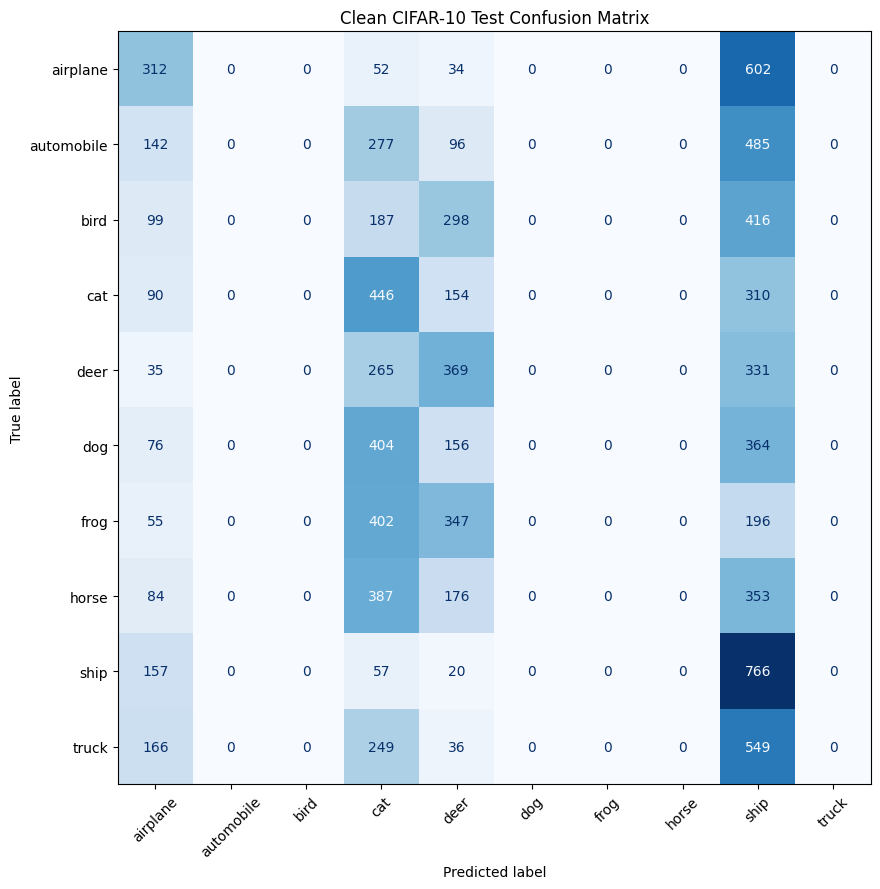

In [28]:
model = selected_models[42]

clean_pred = get_predictions(model, X_clean)
shift_pred = get_predictions(model, X_shift)

# Per-class clean test accuracy
print("Per-class accuracy on clean test set:")
for class_id, class_name in enumerate(CLASS_NAMES):
    mask = y_clean == class_id
    class_acc = (
        np.mean(clean_pred[mask] == y_clean[mask])
        if np.any(mask)
        else float("nan")
    )
    print(f"{class_name:12s}: {class_acc:.4f}")

# Classification report
print("\nClean test classification report:")
print(
    classification_report(
        y_clean,
        clean_pred,
        labels=list(range(10)),
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(y_clean, clean_pred, labels=list(range(10)))

fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)
ax.set_title("Clean CIFAR-10 Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [29]:
model.save("cifar10_inception_selected.keras")

results_df.to_csv("cifar10_augmentation_runs.csv", index=False)
summary.to_csv("cifar10_augmentation_summary.csv")
reg_df.to_csv("cifar10_regularization_runs.csv", index=False)
reg_summary.to_csv("cifar10_regularization_summary.csv")

print("Saved selected model and experiment CSV files.")

Saved selected model and experiment CSV files.
